# Loft25 Customer Returns — Modular Analysis & Predictive Modeling

This notebook provides an end-to-end data audit, exploratory analysis, and leak-free predictive modeling pipeline for **Loft25** (*Gardenista* & *Game Over*). Every sub-step follows a clean **Title → Explanation → Small Code Block** modular system.

**Module Map:**
- **Module 1** (`1.1`–`1.4`): Environment setup, auto-path detection (Colab & local), figure output directory, and data loading
- **Module 2** (`2.1`–`2.4`): Data quality audit, cleaning, cross-table integrity, and anomaly handling
- **Module 3** (`3.1`–`3.2`): Relational joins on verified primary/composite keys (separating ML vs. EDA tables)
- **Module 4** (`4.1`–`4.7`): Exploratory Data Analysis (KPIs, brands, channels, seasonality, couriers, return costs, SKUs)
- **Module 5** (`5.1`–`5.6`): Checkout-time feature engineering, customer-grouped split, OOF SKU encoding, and model preprocessors
- **Module 6** (`6.1`–`6.5`): Imbalance-aware modeling — Logistic Regression, Tuned Native-Categorical XGBoost, LightGBM, and TabNet
- **Module 7** (`7.1`–`7.4`): Model leaderboard, ROC/PR curves, SHAP global explainability, and cost-sensitive £ threshold optimization
- **Module 8** (`8.1`–`8.3`): Forward-in-time chronological validation (`2025` → `2026`) vs. customer-grouped generalization
- **Module 9** (`9.1`–`9.4`): Return scrap-risk triage model (`Returns.xlsx`) and actionable business recommendations

# Module 1: Environment Setup & Data Loading

Verify dependencies, import core libraries, initialize figure export paths, and load all 4 datasets seamlessly in either Google Colab (`/content`) or a local workspace.

### 1.1 Install Optional Packages

Checks for optional analytical and modeling libraries (`openpyxl`, `seaborn`, `xgboost`, `lightgbm`, `pytorch-tabnet`, `shap`) and installs only missing packages.

- **Why:** Ensures one-click reproducibility in Google Colab or fresh local environments.

In [1]:
import importlib.util
import subprocess
import sys

required = {
    "openpyxl": "openpyxl",
    "seaborn": "seaborn",
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "pytorch_tabnet": "pytorch-tabnet",
    "shap": "shap",
}

for module_name, pip_name in required.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
print("All required packages are available.")

All required packages are available.


### 1.2 Core Imports, Styling & Output Directories

Imports core packages, fixes `RANDOM_STATE = 42` for reproducibility, sets Seaborn styling, and ensures the `figures/` folder exists for high-DPI chart exports.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

### 1.3 Locate Data Directory & Load All 4 Datasets

Auto-detects whether the 4 dataset files are in the current folder (`.`) or Google Colab's `/content` directory, then loads them into memory.

- **Outputs:** `customer_orders_df`, `order_lines_df`, `returns_df`, `returns_by_sku_df`.

In [3]:
CANDIDATE_DIRS = [Path("."), Path("/content")]
DATA_DIR = next(
    (d for d in CANDIDATE_DIRS if (d / "Loft25_BCU_04_P4_order_lines.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Place the 4 dataset files in the working directory or /content.")

customer_orders_df = pd.read_excel(DATA_DIR / "Project 4 & 5 - customer orders.xlsx")
returns_df = pd.read_excel(DATA_DIR / "Project 4 & 5 - Returns.xlsx")
order_lines_df = pd.read_csv(DATA_DIR / "Loft25_BCU_04_P4_order_lines.csv")
returns_by_sku_df = pd.read_csv(DATA_DIR / "Loft25_BCU_05_P4_returns_by_SKU.csv")

print(f"Loaded datasets from: {DATA_DIR.resolve()}")

Loaded datasets from: C:\Users\promi\Downloads\jakir


### 1.4 Dataset Inventory & Schema Overview

Prints a compact table of row counts, column counts, and column names across all four tables to confirm exact schemas before cleaning.

In [4]:
datasets = {
    "customer_orders_df": customer_orders_df,
    "order_lines_df": order_lines_df,
    "returns_df": returns_df,
    "returns_by_sku_df": returns_by_sku_df,
}

summary_rows = [
    {"Dataset": name, "Rows": df.shape[0], "Cols": df.shape[1], "Columns": ", ".join(df.columns)}
    for name, df in datasets.items()
]
display(pd.DataFrame(summary_rows))

,Dataset,Rows,Cols,Columns
0,customer_orders_df,31410,6,"Order ref, Customer ref, Order date, Brand, Ch..."
1,order_lines_df,34305,15,"Order ref, Order date, Month, Brand, Channel, ..."
2,returns_df,1523,20,"Order ref, Customer ref, SKU, Brand, Channel, ..."
3,returns_by_sku_df,1458,10,"SKU, Brand, Units sold, Units returned, Units ..."


# Module 2: Data Quality Audit & Cleaning

Audit null values, duplicates, date types, cross-table key integrity, and pricing/discount outliers before merging or modeling.

### 2.1 Missing Value & Exact Duplicate Audit

Checks every table for missing values and exact duplicate rows.

- **Expected Finding:** Only `returns_df` contains missing data — a 100% blank Excel separator column (`Unnamed: 14`).

In [5]:
for name, df in datasets.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    dups = df.duplicated().sum()
    print(f"=== {name} | exact duplicates: {dups} ===")
    if len(nulls) > 0:
        display(pd.DataFrame({"Missing Count": nulls, "Missing %": (nulls / len(df) * 100).round(2)}))
    else:
        print("  No missing values.\n")

=== customer_orders_df | exact duplicates: 0 ===
  No missing values.

=== order_lines_df | exact duplicates: 0 ===
  No missing values.

=== returns_df | exact duplicates: 0 ===


,Missing Count,Missing %
Unnamed: 14,1523,100.0000


=== returns_by_sku_df | exact duplicates: 0 ===
  No missing values.



### 2.2 Drop Empty Columns & Standardize Dates

Drops empty `Unnamed:` placeholder columns from `returns_df` and converts all date columns to consistent `datetime64[ns]` types.

In [6]:
unnamed_cols = [c for c in returns_df.columns if str(c).startswith("Unnamed:")]
if unnamed_cols:
    returns_df = returns_df.drop(columns=unnamed_cols)
    print(f"Dropped empty columns from returns_df: {unnamed_cols}")

order_lines_df["Order date"] = pd.to_datetime(order_lines_df["Order date"])
customer_orders_df["Order date"] = pd.to_datetime(customer_orders_df["Order date"])
returns_df["Order date"] = pd.to_datetime(returns_df["Order date"])
returns_df["Return date"] = pd.to_datetime(returns_df["Return date"])

print("Updated returns_df shape:", returns_df.shape)
print("Order date span:", order_lines_df["Order date"].min().date(), "to", order_lines_df["Order date"].max().date())

Dropped empty columns from returns_df: ['Unnamed: 14']
Updated returns_df shape: (1523, 19)
Order date span: 2025-01-05 to 2026-09-30


### 2.3 Cross-Table Key Integrity & Anomaly Inspection

Verifies relational keys and quantifies dataset anomalies:
1. Uniqueness of composite key `('Order ref', 'SKU')` in both `order_lines_df` and `returns_df`.
2. The **10** £0-value returned lines present in `order_lines_df` (`1,533`) but absent from `returns_df` (`1,523`).
3. **3** rows with `Line discount > 100` (`200%` on 2-unit £0 rows) and **724** zero-price lines.

In [7]:
ol_key_dups = order_lines_df.duplicated(subset=["Order ref", "SKU"]).sum()
ret_key_dups = returns_df.duplicated(subset=["Order ref", "SKU"]).sum()
orders_overlap = set(order_lines_df["Order ref"]) == set(customer_orders_df["Order ref"])

ol_ret_keys = set(zip(order_lines_df.loc[order_lines_df["Returned"] == 1, "Order ref"],
                      order_lines_df.loc[order_lines_df["Returned"] == 1, "SKU"]))
rd_keys = set(zip(returns_df["Order ref"], returns_df["SKU"]))

print(f"Duplicate (Order ref, SKU) -> order_lines: {ol_key_dups}, returns_df: {ret_key_dups}")
print(f"Exact Order ref match (order_lines == customer_orders): {orders_overlap}")
print(f"Returned lines in order_lines missing from returns_df: {len(ol_ret_keys - rd_keys)}")
print(f"Rows with Line discount > 100: {(order_lines_df['Line discount'] > 100).sum()}")
print(f"Rows with Unit price inc VAT == 0: {(order_lines_df['Unit price inc VAT'] == 0).sum()}")

Duplicate (Order ref, SKU) -> order_lines: 0, returns_df: 0
Exact Order ref match (order_lines == customer_orders): True
Returned lines in order_lines missing from returns_df: 10
Rows with Line discount > 100: 3
Rows with Unit price inc VAT == 0: 724


### 2.4 Clean Discount Outliers & Flag Zero-Value Orders

Creates two clean features while leaving raw columns untouched:
- `Line_discount_clean`: clips anomalous `200` values into `[0, 100]`.
- `Is_zero_value`: marks £0-priced manual/replacement/100%-discount lines.

In [8]:
order_lines_df["Line_discount_clean"] = order_lines_df["Line discount"].clip(lower=0, upper=100)
order_lines_df["Is_zero_value"] = (order_lines_df["Unit price inc VAT"] == 0).astype(int)

print("Line_discount_clean range:",
      order_lines_df["Line_discount_clean"].min(), "to", order_lines_df["Line_discount_clean"].max())
print("Zero-value line count:", order_lines_df["Is_zero_value"].sum())

Line_discount_clean range: 0.0 to 100.0
Zero-value line count: 724


# Module 3: Relational Merging

Build a clean pre-purchase master table for ML (`master_df`) and a composite-key enriched table strictly for EDA (`eda_df`), preventing row explosions and target leakage.

### 3.1 Merge Order Lines with Customer Orders (Pre-Purchase Master)

Attaches `Customer ref` and `Postcode area` from `customer_orders_df` onto `order_lines_df` using `'Order ref'` (`validate='many_to_one'`).

- **Output:** `master_df` (34,305 rows, zero duplicate columns, safe for downstream ML).

In [9]:
cust_cols = ["Order ref", "Customer ref", "Postcode area"]
master_df = order_lines_df.merge(
    customer_orders_df[cust_cols],
    on="Order ref",
    how="left",
    validate="many_to_one",
)

assert len(master_df) == len(order_lines_df), "Row count changed after merge!"
print("master_df shape:", master_df.shape)
display(master_df[["Order ref", "Customer ref", "Order date", "Brand", "Channel", "Postcode area", "SKU", "Returned"]].head(5))

master_df shape: (34305, 19)


,Order ref,Customer ref,Order date,Brand,Channel,Postcode area,SKU,Returned
0,O000020,C000010,2025-01-09,Gardenista,Website (Shopify),NE10,GP G71 Steamer Harvest Green,0
1,O000019,C000009,2025-01-09,Gardenista,Amazon,BS49,PLT E12 Harvest Grey,1
2,O000024,C000014,2025-01-11,Gardenista,eBay,HA6,GP G45 B398 Grey,0
3,O000025,C000015,2025-01-11,Gardenista,Amazon,LS3,LGP10 Harvest Green,0
4,O000026,C000016,2025-01-11,Gardenista,eBay,B43,DCC PU Coated Green,0


### 3.2 Join Return Details on Composite Key (EDA Only)

Left-joins `returns_df` onto `master_df` using the verified composite key `['Order ref', 'SKU']` (`validate='one_to_one'`).

- **Guardrail:** `eda_df` and `returns_by_sku_df` contain post-return/full-dataset outcomes and are used **only in EDA** (Module 4) or dedicated return triage (Module 9), never as checkout ML features.

In [10]:
ret_detail_cols = [
    "Order ref", "SKU", "Return date", "Days to return", "Return reason",
    "Customer feedback", "Return shipping cost", "Unit cost of goods",
    "Scrapped", "Write-off cost", "Total return cost",
]
eda_df = master_df.merge(
    returns_df[ret_detail_cols],
    on=["Order ref", "SKU"],
    how="left",
    validate="one_to_one",
)

print("eda_df shape:", eda_df.shape)
print("Matched return detail rows:", eda_df["Return reason"].notna().sum())

eda_df shape: (34305, 28)
Matched return detail rows: 1523


# Module 4: Exploratory Data Analysis (EDA)

Quantify return rates, seasonality, courier performance, return reasons, scrap write-offs, and SKU risk — automatically saving publication-ready charts to `figures/`.

### 4.1 Overall Return KPIs & Financial Impact

Computes high-level operational and financial KPIs across all orders, lines, units, refunds, and direct return costs.

In [11]:
kpis = {
    "Total Order Lines": f"{len(master_df):,}",
    "Distinct Orders": f"{master_df['Order ref'].nunique():,}",
    "Distinct Customers": f"{master_df['Customer ref'].nunique():,}",
    "Line Return Rate": f"{master_df['Returned'].mean() * 100:.2f}%",
    "Order Return Rate": f"{master_df.groupby('Order ref')['Returned'].max().mean() * 100:.2f}%",
    "Unit Return Rate": f"{master_df['Units returned'].sum() / master_df['Qty'].sum() * 100:.2f}%",
    "Gross Sales Value (inc VAT)": f"£{master_df['Line value inc VAT'].sum():,.2f}",
    "Total Refunded Value": f"£{master_df['Refund amount'].sum():,.2f}",
    "Total Operational Return Cost": f"£{returns_df['Total return cost'].sum():,.2f}",
    "Return Scrap Rate": f"{(returns_df['Scrapped'] == 'Yes').mean() * 100:.2f}%",
}
display(pd.DataFrame(list(kpis.items()), columns=["Metric", "Value"]))

,Metric,Value
0,Total Order Lines,"34,305"
1,Distinct Orders,"31,410"
2,Distinct Customers,"22,854"
3,Line Return Rate,4.47%
4,Order Return Rate,4.59%
5,Unit Return Rate,4.83%
6,Gross Sales Value (inc VAT),"£1,622,434.24"
7,Total Refunded Value,"£79,405.56"
8,Total Operational Return Cost,"£16,317.26"
9,Return Scrap Rate,29.61%


### 4.2 Brand Performance & Return Rates

Compares *Gardenista* vs. *Game Over* using distinct orders (`nunique`) alongside line counts (`count`) and exports `figures/01_brand_returns.png`.

,Brand,Order_Lines,Distinct_Orders,Return_Rate_Pct,Avg_Line_Value
0,Game Over,5065,4347,2.0336,62.8597
1,Gardenista,29240,27089,4.8906,44.5982


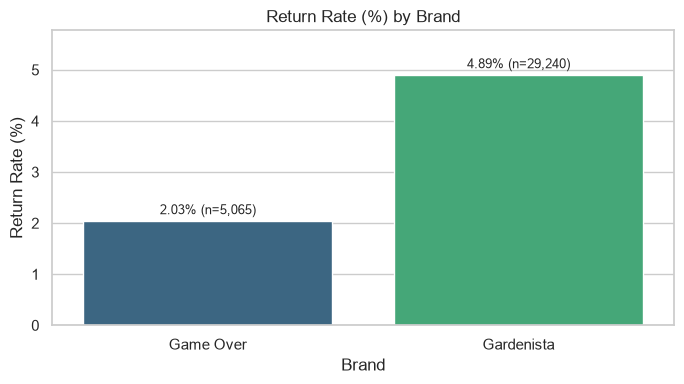

In [12]:
brand_eda = (
    master_df.groupby("Brand", as_index=False)
    .agg(
        Order_Lines=("Order ref", "count"),
        Distinct_Orders=("Order ref", "nunique"),
        Return_Rate_Pct=("Returned", lambda s: s.mean() * 100),
        Avg_Line_Value=("Line value inc VAT", "mean"),
    )
)
display(brand_eda)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=brand_eda, x="Brand", y="Return_Rate_Pct", hue="Brand", palette="viridis", legend=False, ax=ax)
for patch, n in zip(ax.patches, brand_eda["Order_Lines"]):
    ax.annotate(f"{patch.get_height():.2f}% (n={n:,})", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_title("Return Rate (%) by Brand")
ax.set_ylabel("Return Rate (%)")
ax.set_ylim(0, brand_eda["Return_Rate_Pct"].max() * 1.18)
plt.tight_layout()
fig.savefig(FIG_DIR / "01_brand_returns.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Channel Performance with Sample-Size Context

Compares return rates across sales channels sorted by volume, annotating `n` above each bar so low-volume channels (`Mirakl MP`, `n=11`) are properly contextualized. Exports `figures/02_channel_returns.png`.

,Channel,Order_Lines,Distinct_Orders,Returned_Lines,Return_Rate_Pct,Avg_Line_Value
0,Amazon,21678,20207,945,4.3593,47.1735
6,Website (Shopify),7047,5985,273,3.8740,51.1511
4,The Range,3492,3252,226,6.4719,48.3497
7,eBay,1399,1309,57,4.0743,45.2366
1,Direct/Manual,332,313,5,1.5060,0.9213
5,TikTok Shop,297,285,20,6.7340,15.7193
3,TEMU EU,49,49,3,6.1224,38.2459
2,Mirakl MP,11,10,4,36.3636,34.0173


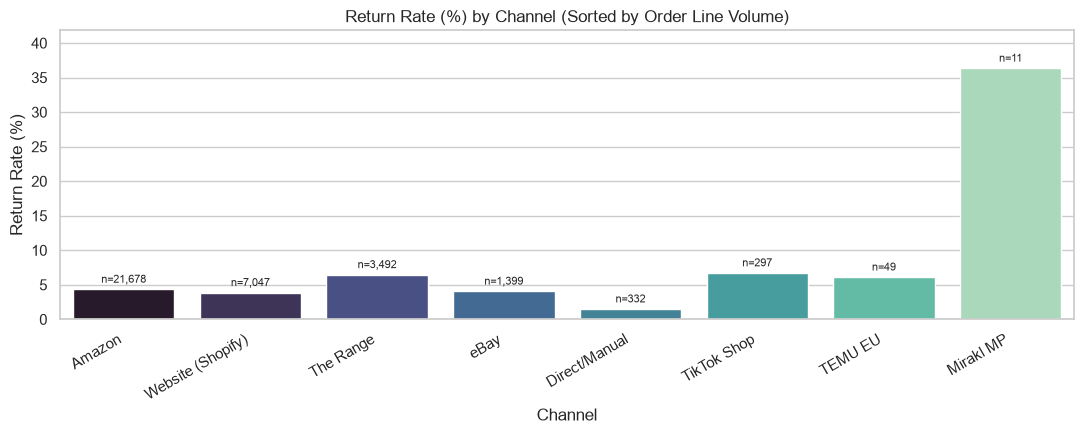

In [13]:
channel_eda = (
    master_df.groupby("Channel", as_index=False)
    .agg(
        Order_Lines=("Order ref", "count"),
        Distinct_Orders=("Order ref", "nunique"),
        Returned_Lines=("Returned", "sum"),
        Return_Rate_Pct=("Returned", lambda s: s.mean() * 100),
        Avg_Line_Value=("Line value inc VAT", "mean"),
    )
    .sort_values("Order_Lines", ascending=False)
)
display(channel_eda)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=channel_eda, x="Channel", y="Return_Rate_Pct", hue="Channel", palette="mako", legend=False, ax=ax)
for patch, n in zip(ax.patches, channel_eda["Order_Lines"]):
    ax.annotate(f"n={n:,}", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.set_title("Return Rate (%) by Channel (Sorted by Order Line Volume)")
ax.set_ylabel("Return Rate (%)")
ax.set_ylim(0, channel_eda["Return_Rate_Pct"].max() * 1.15)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_channel_returns.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Monthly Volume & Return Rate Seasonality by Brand

Visualizes monthly order volume and return rates across the 21-month span, revealing *Gardenista*'s spring/summer peak and *Game Over*'s July 2025 launch with a strong Q4 peak. Exports `figures/03_monthly_seasonality.png`.

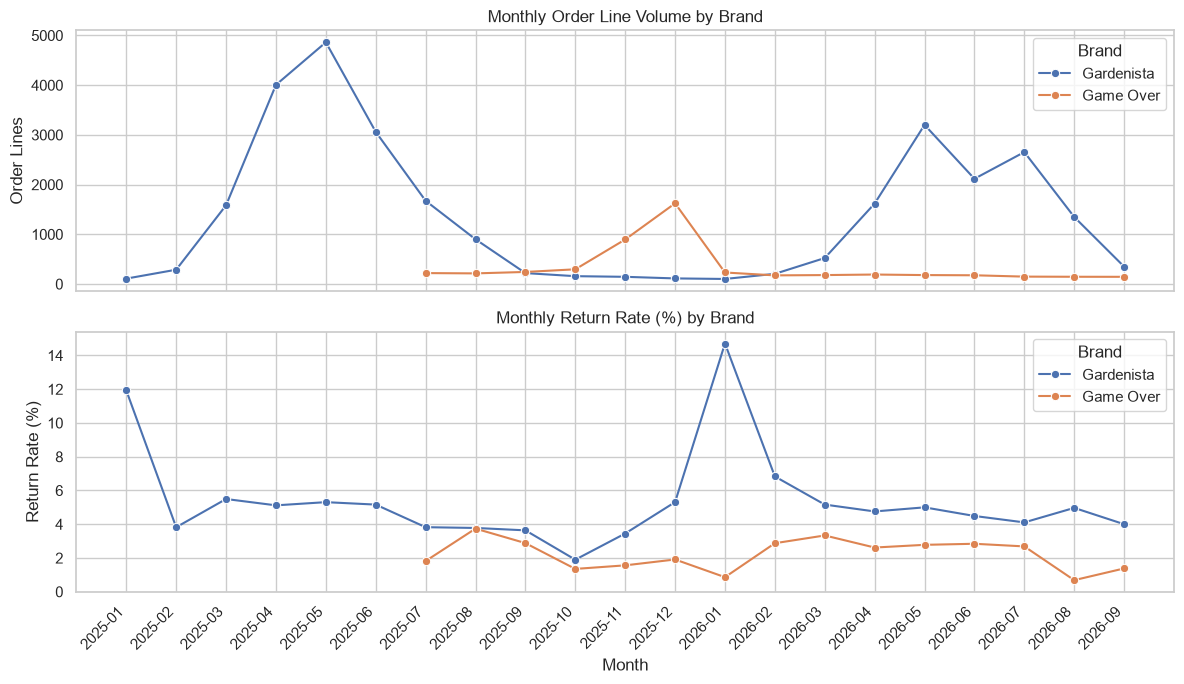

In [14]:
monthly_brand = (
    master_df.groupby(["Month", "Brand"], as_index=False)
    .agg(Lines=("Order ref", "count"), Return_Rate_Pct=("Returned", lambda s: s.mean() * 100))
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.lineplot(data=monthly_brand, x="Month", y="Lines", hue="Brand", marker="o", ax=axes[0])
axes[0].set_title("Monthly Order Line Volume by Brand")
axes[0].set_ylabel("Order Lines")

sns.lineplot(data=monthly_brand, x="Month", y="Return_Rate_Pct", hue="Brand", marker="o", ax=axes[1])
axes[1].set_title("Monthly Return Rate (%) by Brand")
axes[1].set_ylabel("Return Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "03_monthly_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Courier Service & Line Value Distribution

Evaluates return rates by `Courier service` and compares line values for returned vs. kept items. Exports `figures/04_line_value_by_return.png`.

,Courier service,Order_Lines,Return_Rate_Pct
2,DPD TWO DAY GUK,20821,4.6972
5,EVRI MAINLAND 48,4437,4.8907
3,Default,4300,4.3256
1,DPD TWO DAY GO,3350,2.0000
4,EVRI LIGHT AND LARGE,1351,5.4034
6,EVRI NEXT DAY,40,20.0000
0,BT Postcode - Do not Ship,6,66.6667


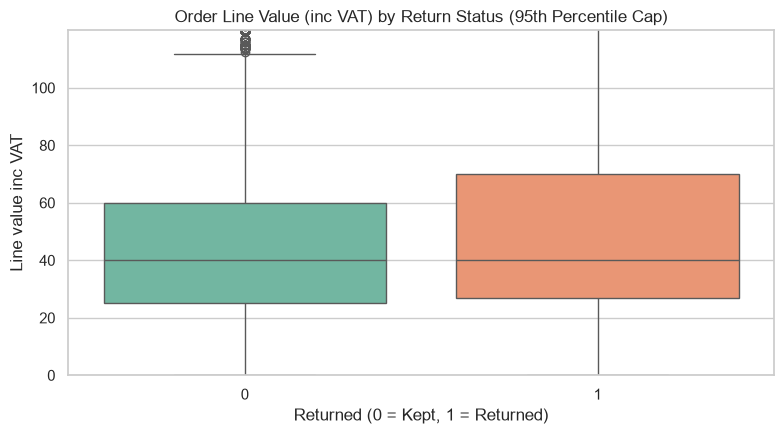

In [15]:
courier_eda = (
    master_df.groupby("Courier service", as_index=False)
    .agg(Order_Lines=("Order ref", "count"), Return_Rate_Pct=("Returned", lambda s: s.mean() * 100))
    .sort_values("Order_Lines", ascending=False)
)
display(courier_eda)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=master_df, x="Returned", y="Line value inc VAT", hue="Returned", palette="Set2", legend=False, ax=ax)
ax.set_ylim(0, master_df["Line value inc VAT"].quantile(0.95))
ax.set_title("Order Line Value (inc VAT) by Return Status (95th Percentile Cap)")
ax.set_xlabel("Returned (0 = Kept, 1 = Returned)")
plt.tight_layout()
fig.savefig(FIG_DIR / "04_line_value_by_return.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Return Reasons, Scrap Rates & Financial Cost Breakdown

Ranks the 9 return reasons in `returns_df` by total direct return cost (`Shipping + Write-off`) alongside scrap percentages and average return lag. Exports `figures/05_return_reason_costs.png`.

,Return reason,Return_Count,Scrap_Rate_Pct,Avg_Days_To_Return,Total_Refunds,Total_Return_Cost
3,Faulty / poor quality,229,65.9389,17.2838,"11,297.0600","3,912.8100"
1,Damaged on arrival,173,87.8613,16.8150,"9,254.5300","3,796.3700"
7,Smell / stains,90,95.5556,16.3778,"5,150.6800","2,255.1700"
2,Does not fit,330,5.4545,17.4818,"18,401.4500","2,024.4400"
5,No longer needed,229,5.2402,16.0699,"11,895.7500","1,356.4300"
4,Item not as described / different to photos,217,4.6083,17.5300,"11,876.9500","1,312.7500"
6,Ordered by mistake,113,4.4248,18.6549,"4,937.7700",662.9400
0,Arrived too late,75,8.0000,17.1467,"3,364.1200",502.5500
8,Wrong item sent,67,16.4179,17.5224,"3,227.2500",493.8000


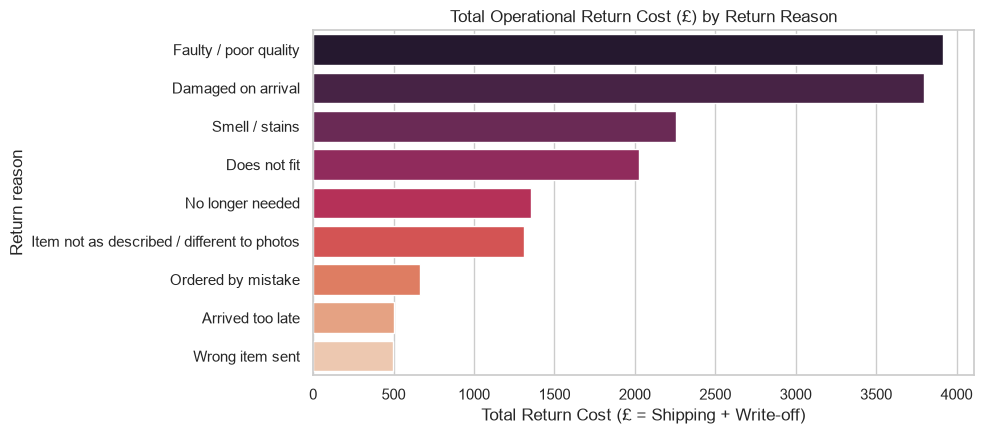

In [16]:
reason_eda = (
    returns_df.groupby("Return reason", as_index=False)
    .agg(
        Return_Count=("Order ref", "count"),
        Scrap_Rate_Pct=("Scrapped", lambda s: (s == "Yes").mean() * 100),
        Avg_Days_To_Return=("Days to return", "mean"),
        Total_Refunds=("Refund amount", "sum"),
        Total_Return_Cost=("Total return cost", "sum"),
    )
    .sort_values("Total_Return_Cost", ascending=False)
)
display(reason_eda)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=reason_eda, y="Return reason", x="Total_Return_Cost", hue="Return reason", palette="rocket", legend=False, ax=ax)
ax.set_title("Total Operational Return Cost (£) by Return Reason")
ax.set_xlabel("Total Return Cost (£ = Shipping + Write-off)")
plt.tight_layout()
fig.savefig(FIG_DIR / "05_return_reason_costs.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.7 High-Volume High-Risk SKUs (Filtered View)

Summarizes `Flag` categories across all 1,458 SKUs and filters to `Units sold >= 20` so single-unit returns do not dominate product-quality prioritization.

In [17]:
print("SKU Flag distribution (all 1,458 SKUs):")
display(returns_by_sku_df["Flag"].value_counts().rename_axis("Flag").to_frame("SKU Count"))

high_vol_risk = (
    returns_by_sku_df[returns_by_sku_df["Units sold"] >= 20]
    .assign(Return_Rate_Pct=lambda d: (1 - d["Kept rate"]) * 100)
    .sort_values(["Return_Rate_Pct", "Refund value"], ascending=False)
    .head(15)
)
print("Top 15 Highest Return-Rate SKUs (Units sold >= 20):")
display(high_vol_risk[["SKU", "Brand", "Units sold", "Units returned", "Return_Rate_Pct", "Flag", "Refund value"]])

SKU Flag distribution (all 1,458 SKUs):


,SKU Count
Flag,
Green,1380
Orange,45
Red,33


Top 15 Highest Return-Rate SKUs (Units sold >= 20):


,SKU,Brand,Units sold,Units returned,Return_Rate_Pct,Flag,Refund value
261,CS H1 Linoso Sand,Gardenista,40,23,57.5000,Red,298.3100
395,GP G1 PD Palm,Gardenista,25,8,32.0000,Orange,115.7600
316,PDG1 Duck Teal,Gardenista,33,10,30.3000,Orange,349.7000
219,GP G2 Two Part Pad B398 Grey 4pk,Gardenista,48,14,29.1700,Green,"1,111.6000"
280,LGP9 Harvest Stone,Gardenista,38,10,26.3200,Green,344.7000
432,CNP 2 Seater C6628 Green,Gardenista,23,6,26.0900,Green,124.8500
491,GP G77 Folding Harvest Green,Gardenista,20,5,25.0000,Green,224.9600
392,CC CD1 Arabesque Purple,Gardenista,25,6,24.0000,Green,59.9400
233,CS Malia Ikea Klippan Pacific,Gardenista,46,11,23.9100,Green,714.6700
468,PDG1 Duck Amber Gold,Gardenista,21,5,23.8100,Green,174.8400


# Module 5: Feature Engineering & Leak-Free Data Preparation

Engineer strictly pre-purchase features, partition by `Customer ref` into 70/15/15 Train/Val/Test splits, compute 5-fold out-of-fold SKU target encoding, and prepare model-specific inputs.

### 5.1 Engineer Order, Product & Temporal Pre-Purchase Features

Extracts signals known **before dispatch** (zero post-return leakage):
- **Temporal:** month, day of week, weekend indicator
- **Basket context:** lines per order, total order value, total order qty, line share of order value
- **Product & Geo:** `sku_prefix` (product family), `pack_size` (`2pk`, `4pk`, etc.), `is_bt_postcode` (Northern Ireland shipping flag)

In [18]:
feat_df = master_df.copy()

# Temporal features
feat_df["order_month"] = feat_df["Order date"].dt.month
feat_df["order_dayofweek"] = feat_df["Order date"].dt.dayofweek
feat_df["is_weekend"] = (feat_df["order_dayofweek"] >= 5).astype(int)

# Basket / order-level features
order_agg = feat_df.groupby("Order ref").agg(
    order_line_count=("SKU", "count"),
    order_total_value=("Line value inc VAT", "sum"),
    order_total_qty=("Qty", "sum"),
)
feat_df = feat_df.merge(order_agg, on="Order ref", how="left")
feat_df["line_value_share"] = np.where(
    feat_df["order_total_value"] > 0,
    feat_df["Line value inc VAT"] / feat_df["order_total_value"],
    0.0,
)

# Product & UK postcode signals
feat_df["sku_prefix"] = feat_df["SKU"].str.split().str[0].fillna("OTHER")
pack_match = feat_df["SKU"].str.extract(r"(\d+)\s*[pP][kK]", expand=False)
feat_df["pack_size"] = pd.to_numeric(pack_match, errors="coerce").fillna(1).astype(int)
feat_df["is_bt_postcode"] = feat_df["Postcode area"].astype(str).str.upper().str.startswith("BT").astype(int)

print("Engineered feature table shape:", feat_df.shape)

Engineered feature table shape: (34305, 29)


### 5.2 Engineer Past-Only Customer Order History

Computes `cust_prior_orders` and `cust_prior_spend` at the order level, chronologically sorted and strictly excluding the current order (preventing intra-order and future leakage).

In [19]:
order_hist = (
    feat_df.groupby(["Customer ref", "Order ref", "Order date"], as_index=False)
    .agg(order_val=("Line value inc VAT", "sum"))
    .sort_values(["Customer ref", "Order date", "Order ref"])
)

order_hist["cust_prior_orders"] = order_hist.groupby("Customer ref").cumcount()
order_hist["cust_prior_spend"] = (
    order_hist.groupby("Customer ref")["order_val"].cumsum() - order_hist["order_val"]
)

feat_df = feat_df.merge(
    order_hist[["Order ref", "cust_prior_orders", "cust_prior_spend"]],
    on="Order ref",
    how="left",
)
display(feat_df[["cust_prior_orders", "cust_prior_spend"]].describe().T[["mean", "50%", "max"]])

,mean,50%,max
cust_prior_orders,0.6722,0.0000,11.0000
cust_prior_spend,32.7268,0.0000,877.1100


### 5.3 Customer-Grouped Train / Validation / Test Split (70% / 15% / 15%)

Splits `feat_df` using `GroupShuffleSplit` grouped by `Customer ref` so no customer or multi-line order crosses split boundaries.

In [20]:
from sklearn.model_selection import GroupShuffleSplit

y_all = feat_df["Returned"].astype(int)
groups_all = feat_df["Customer ref"]

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(feat_df, y_all, groups=groups_all))

trainval_df = feat_df.iloc[trainval_idx].copy()
test_df = feat_df.iloc[test_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
tr_rel_idx, val_rel_idx = next(gss_val.split(trainval_df, trainval_df["Returned"], groups=trainval_df["Customer ref"]))

train_df = trainval_df.iloc[tr_rel_idx].copy()
val_df = trainval_df.iloc[val_rel_idx].copy()

for split_name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{split_name:5s}: rows={len(split_df):5d} | customers={split_df['Customer ref'].nunique():5d} | return_rate={split_df['Returned'].mean()*100:.2f}%")

Train: rows=24137 | customers=15997 | return_rate=4.50%
Val  : rows= 5059 | customers= 3428 | return_rate=4.25%
Test : rows= 5109 | customers= 3429 | return_rate=4.54%


### 5.4 Reusable Out-of-Fold (OOF) Smoothed SKU Target Encoder

Defines a reusable `add_oof_sku_encoding(tr, va, te)` helper that computes 5-fold customer-grouped out-of-fold smoothed SKU return rates (`m = 20`) on training data and maps full-train priors to validation and test splits.

- **Why:** Prevents target-encoding overfitting on rare SKUs and can be reused cleanly in Module 8 (Temporal Split).

In [21]:
from sklearn.model_selection import StratifiedGroupKFold

def add_oof_sku_encoding(tr, va, te, smoothing_m=20.0):
    tr, va, te = tr.copy(), va.copy(), te.copy()
    global_prior = tr["Returned"].mean()
    oof = np.full(len(tr), global_prior, dtype=float)
    sgkf = StratifiedGroupKFold(n_splits=5)
    for f_tr, f_va in sgkf.split(tr, tr["Returned"], groups=tr["Customer ref"]):
        st = tr.iloc[f_tr].groupby("SKU")["Returned"].agg(["count", "mean"])
        sm = (st["count"] * st["mean"] + smoothing_m * global_prior) / (st["count"] + smoothing_m)
        oof[f_va] = tr.iloc[f_va]["SKU"].map(sm).fillna(global_prior).to_numpy()
    tr["sku_ret_rate_enc"] = oof
    full_st = tr.groupby("SKU")["Returned"].agg(["count", "mean"])
    full_sm = (full_st["count"] * full_st["mean"] + smoothing_m * global_prior) / (full_st["count"] + smoothing_m)
    va["sku_ret_rate_enc"] = va["SKU"].map(full_sm).fillna(global_prior)
    te["sku_ret_rate_enc"] = te["SKU"].map(full_sm).fillna(global_prior)
    return tr, va, te

train_df, val_df, test_df = add_oof_sku_encoding(train_df, val_df, test_df)
print(f"OOF SKU range (train): {train_df['sku_ret_rate_enc'].min():.4f} to {train_df['sku_ret_rate_enc'].max():.4f}")

OOF SKU range (train): 0.0031 to 0.2091


### 5.5 Define Feature Lists & Linear / Native-Categorical DataFrames

Defines `CAT_COLS` (4) and `NUM_COLS` (18), configures `preprocess_linear` (`OneHotEncoder(min_frequency=50)` + `StandardScaler`), and builds `pd.CategoricalDtype` DataFrames (`X_*_cat`) for native categorical splitting in **XGBoost** and **LightGBM**.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT_COLS = ["Brand", "Channel", "Courier service", "sku_prefix"]
NUM_COLS = [
    "Qty", "Unit price inc VAT", "Line value inc VAT", "Line_discount_clean",
    "Promotion applied", "Is_zero_value", "order_month", "order_dayofweek",
    "is_weekend", "order_line_count", "order_total_value", "order_total_qty",
    "line_value_share", "pack_size", "is_bt_postcode", "cust_prior_orders",
    "cust_prior_spend", "sku_ret_rate_enc",
]
FEATURE_COLS = CAT_COLS + NUM_COLS

X_train_raw, y_train = train_df[FEATURE_COLS], train_df["Returned"].astype(int).to_numpy()
X_val_raw, y_val = val_df[FEATURE_COLS], val_df["Returned"].astype(int).to_numpy()
X_test_raw, y_test = test_df[FEATURE_COLS], test_df["Returned"].astype(int).to_numpy()

preprocess_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), CAT_COLS),
    ("num", StandardScaler(), NUM_COLS),
])

def build_native_cat_frames(tr_df, va_df, te_df):
    X_tr, X_va, X_te = tr_df[FEATURE_COLS].copy(), va_df[FEATURE_COLS].copy(), te_df[FEATURE_COLS].copy()
    for col in CAT_COLS:
        cats = sorted(X_tr[col].astype(str).unique())
        cat_set = set(cats)
        X_tr[col] = pd.Categorical(X_tr[col].astype(str), categories=cats)
        X_va[col] = pd.Categorical(X_va[col].astype(str).where(X_va[col].astype(str).isin(cat_set)), categories=cats)
        X_te[col] = pd.Categorical(X_te[col].astype(str).where(X_te[col].astype(str).isin(cat_set)), categories=cats)
    return X_tr, X_va, X_te

X_train_cat, X_val_cat, X_test_cat = build_native_cat_frames(train_df, val_df, test_df)
print(f"Configured {len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(NUM_COLS)} numeric.")

Configured 22 features: 4 categorical, 18 numeric.


### 5.6 Encode Embedding-Safe Arrays for TabNet

Maps categorical features strictly from `train_df` into `0..K` integer indices (reserving index `K` for unseen validation/test categories) alongside scaled numerics for **TabNet**.

In [23]:
cat_dims = []
X_train_tab = np.zeros((len(train_df), len(FEATURE_COLS)), dtype=np.float32)
X_val_tab = np.zeros((len(val_df), len(FEATURE_COLS)), dtype=np.float32)
X_test_tab = np.zeros((len(test_df), len(FEATURE_COLS)), dtype=np.float32)

for idx, col in enumerate(CAT_COLS):
    cats = sorted(train_df[col].astype(str).unique())
    unk_idx = len(cats)
    mapping = {c: i for i, c in enumerate(cats)}
    cat_dims.append(unk_idx + 1)
    X_train_tab[:, idx] = train_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()
    X_val_tab[:, idx] = val_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()
    X_test_tab[:, idx] = test_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()

num_scaler = StandardScaler()
X_train_tab[:, len(CAT_COLS):] = num_scaler.fit_transform(train_df[NUM_COLS])
X_val_tab[:, len(CAT_COLS):] = num_scaler.transform(val_df[NUM_COLS])
X_test_tab[:, len(CAT_COLS):] = num_scaler.transform(test_df[NUM_COLS])

cat_idxs = list(range(len(CAT_COLS)))
cat_emb_dims = [min(16, max(2, (d + 1) // 2)) for d in cat_dims]
print("TabNet cat_dims:", cat_dims, "| embedding dims:", cat_emb_dims)

TabNet cat_dims: [3, 9, 8, 46] | embedding dims: [2, 5, 4, 16]


# Module 6: Imbalance-Aware Model Training & Tuning (Customer-Grouped Split)

Train four distinct model families — Logistic Regression, Tuned Native-Categorical XGBoost, LightGBM, and TabNet — using validation-only early stopping and threshold tuning.

### 6.1 Validation Threshold Tuner & Evaluation Utility

Defines `tune_threshold(y_val, val_probs)` (maximizing Class-1 F1 on validation only) and `evaluate_model(...)` (reporting ROC-AUC, PR-AUC, Precision, Recall, and F1 on test).

In [24]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

def tune_threshold(y_true, probs):
    prec, rec, thresholds = precision_recall_curve(y_true, probs)
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thresholds[int(np.argmax(f1s))])

def evaluate_model(name, y_true, probs, threshold, verbose=True):
    preds = (probs >= threshold).astype(int)
    if verbose:
        print(f"=== {name} (Test Set | threshold={threshold:.3f}) ===")
        print(classification_report(y_true, preds, zero_division=0))
    return {
        "Model": name,
        "Threshold": round(threshold, 4),
        "ROC_AUC": round(roc_auc_score(y_true, probs), 4),
        "PR_AUC": round(average_precision_score(y_true, probs), 4),
        "Precision_1": round(precision_score(y_true, preds, zero_division=0), 4),
        "Recall_1": round(recall_score(y_true, preds, zero_division=0), 4),
        "F1_1": round(f1_score(y_true, preds, zero_division=0), 4),
    }

model_results = []
val_prob_store = {}
test_prob_store = {}

### 6.2 Model 1 — Balanced Logistic Regression

Trains a regularized Logistic Regression pipeline (`class_weight='balanced'`) over one-hot encoded categoricals and standardized numerics.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("prep", preprocess_linear),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, C=1.0, random_state=RANDOM_STATE)),
])
lr_pipeline.fit(X_train_raw, y_train)

lr_val_probs = lr_pipeline.predict_proba(X_val_raw)[:, 1]
lr_test_probs = lr_pipeline.predict_proba(X_test_raw)[:, 1]
lr_thresh = tune_threshold(y_val, lr_val_probs)

model_results.append(evaluate_model("Logistic Regression (Balanced)", y_test, lr_test_probs, lr_thresh))
val_prob_store["Logistic Regression"] = lr_val_probs
test_prob_store["Logistic Regression"] = lr_test_probs

=== Logistic Regression (Balanced) (Test Set | threshold=0.629) ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      4877
           1       0.09      0.23      0.13       232

    accuracy                           0.86      5109
   macro avg       0.53      0.56      0.53      5109
weighted avg       0.92      0.86      0.89      5109



### 6.3 Model 2 — Tuned Native-Categorical XGBoost

Trains an `XGBClassifier` with **native categorical partitioning (`enable_categorical=True`)**, stronger L1/L2 + child-weight regularization (`max_depth=4`, `min_child_weight=15`, `reg_lambda=10.0`), `scale_pos_weight`, and validation early stopping.

In [26]:
from xgboost import XGBClassifier

neg_pos_ratio = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))

xgb_model = XGBClassifier(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=15,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=10.0,
    scale_pos_weight=neg_pos_ratio,
    tree_method="hist",
    enable_categorical=True,
    max_cat_to_onehot=4,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_model.fit(X_train_cat, y_train, eval_set=[(X_val_cat, y_val)], verbose=False)

xgb_val_probs = xgb_model.predict_proba(X_val_cat)[:, 1]
xgb_test_probs = xgb_model.predict_proba(X_test_cat)[:, 1]
xgb_thresh = tune_threshold(y_val, xgb_val_probs)

model_results.append(evaluate_model("XGBoost (Native Cat + Tuned)", y_test, xgb_test_probs, xgb_thresh))
val_prob_store["XGBoost"] = xgb_val_probs
test_prob_store["XGBoost"] = xgb_test_probs

=== XGBoost (Native Cat + Tuned) (Test Set | threshold=0.527) ===
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      4877
           1       0.10      0.11      0.10       232

    accuracy                           0.91      5109
   macro avg       0.53      0.53      0.53      5109
weighted avg       0.92      0.91      0.92      5109



### 6.4 Model 3 — Balanced LightGBM Classifier

Trains a leaf-wise gradient boosting classifier (`LGBMClassifier`) using native categorical handling, `is_unbalance=True`, conservative leaf regularization (`num_leaves=15`, `min_child_samples=40`), and validation early stopping.

In [27]:
import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    objective="binary",
    metric="average_precision",
    is_unbalance=True,
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=5.0,
    random_state=RANDOM_STATE,
    verbose=-1,
)
lgb_model.fit(
    X_train_cat,
    y_train,
    eval_set=[(X_val_cat, y_val)],
    callbacks=[lgb.early_stopping(30, first_metric_only=True, verbose=False)],
)

lgb_val_probs = lgb_model.predict_proba(X_val_cat)[:, 1]
lgb_test_probs = lgb_model.predict_proba(X_test_cat)[:, 1]
lgb_thresh = tune_threshold(y_val, lgb_val_probs)

model_results.append(evaluate_model("LightGBM (Native Cat + Balanced)", y_test, lgb_test_probs, lgb_thresh))
val_prob_store["LightGBM"] = lgb_val_probs
test_prob_store["LightGBM"] = lgb_test_probs

=== LightGBM (Native Cat + Balanced) (Test Set | threshold=0.578) ===
              precision    recall  f1-score   support

           0       0.96      0.93      0.94      4877
           1       0.10      0.17      0.13       232

    accuracy                           0.90      5109
   macro avg       0.53      0.55      0.54      5109
weighted avg       0.92      0.90      0.91      5109



### 6.5 Model 4 — TabNet Classifier (Embeddings + Balanced Sampling)

Trains `TabNetClassifier` with learned categorical embeddings (`cat_idxs`, `cat_dims`, `cat_emb_dims`), built-in class balancing (`weights=1`), and validation-only early stopping.

In [28]:
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_model = TabNetClassifier(
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=cat_emb_dims,
    seed=RANDOM_STATE,
    verbose=0,
)
tabnet_model.fit(
    X_train=X_train_tab,
    y_train=y_train,
    eval_set=[(X_val_tab, y_val)],
    eval_name=["val"],
    eval_metric=["auc"],
    weights=1,
    max_epochs=30,
    patience=7,
    batch_size=1024,
    virtual_batch_size=128,
)

tab_val_probs = tabnet_model.predict_proba(X_val_tab)[:, 1]
tab_test_probs = tabnet_model.predict_proba(X_test_tab)[:, 1]
tab_thresh = tune_threshold(y_val, tab_val_probs)

model_results.append(evaluate_model("TabNet (Embeddings + Balanced)", y_test, tab_test_probs, tab_thresh))
val_prob_store["TabNet"] = tab_val_probs
test_prob_store["TabNet"] = tab_test_probs


Early stopping occurred at epoch 10 with best_epoch = 3 and best_val_auc = 0.61383


=== TabNet (Embeddings + Balanced) (Test Set | threshold=0.611) ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      4877
           1       0.08      0.19      0.11       232

    accuracy                           0.85      5109
   macro avg       0.52      0.54      0.51      5109
weighted avg       0.92      0.85      0.88      5109



# Module 7: Model Comparison, SHAP Explainability & Cost-Sensitive Thresholding

Compare all four models on held-out test data, inspect global SHAP explanations, and translate risk scores into expected £ net savings.

### 7.1 Side-by-Side Test Performance Leaderboard

Ranks all four models by **PR-AUC** (the primary ranking metric under 4.5% return prevalence).

In [29]:
results_df = pd.DataFrame(model_results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Threshold,ROC_AUC,PR_AUC,Precision_1,Recall_1,F1_1
0,LightGBM (Native Cat + Balanced),0.5781,0.6088,0.0938,0.1034,0.1681,0.1281
1,Logistic Regression (Balanced),0.6285,0.6208,0.0858,0.0904,0.2284,0.1296
2,XGBoost (Native Cat + Tuned),0.5269,0.6063,0.0724,0.0988,0.1078,0.1031
3,TabNet (Embeddings + Balanced),0.6106,0.5947,0.0654,0.0751,0.1940,0.1083


### 7.2 ROC & Precision-Recall Curves Comparison

Plots test-set ROC and Precision-Recall curves side by side for all four models and exports `figures/06_roc_pr_curves.png`.

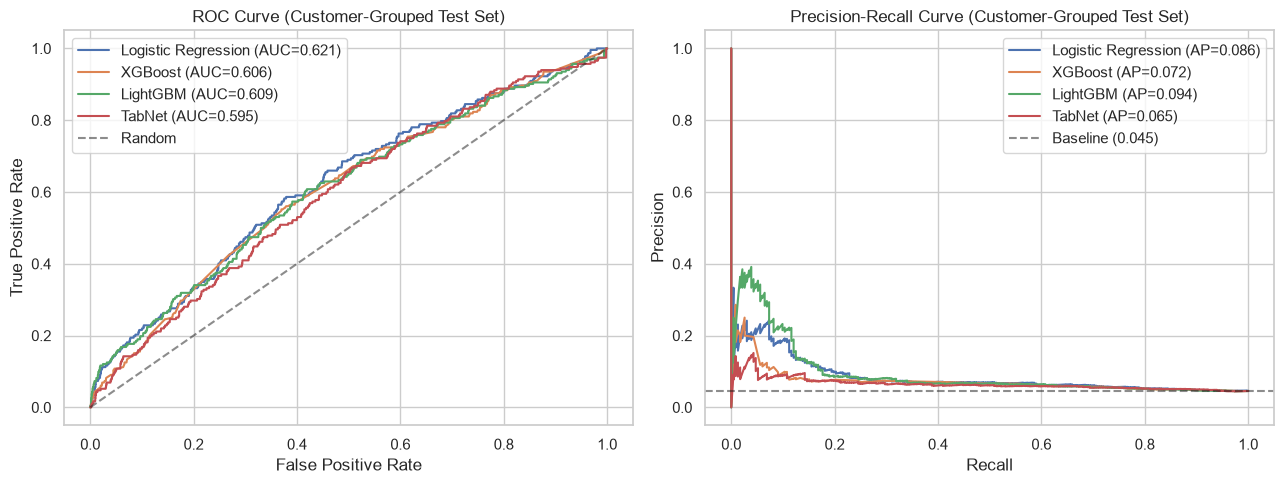

In [30]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probs in test_prob_store.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, probs):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random")
axes[0].set_title("ROC Curve (Customer-Grouped Test Set)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

baseline_rate = y_test.mean()
axes[1].axhline(baseline_rate, color="k", linestyle="--", alpha=0.5, label=f"Baseline ({baseline_rate:.3f})")
axes[1].set_title("Precision-Recall Curve (Customer-Grouped Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "06_roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.3 SHAP Global Feature Explainability (LightGBM)

Computes TreeSHAP values on a 1,500-row sample of the held-out test set using LightGBM to show **both magnitude and direction** of each feature's effect on return risk. Exports `figures/07_shap_summary.png`.

C:\Users\promi\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Feature,Mean_Abs_SHAP
3,sku_prefix,0.2878
21,sku_ret_rate_enc,0.2292
10,order_month,0.1088
6,Line value inc VAT,0.0681
14,order_total_value,0.0569
5,Unit price inc VAT,0.0540
16,line_value_share,0.0407
1,Channel,0.0308
15,order_total_qty,0.0285
0,Brand,0.0261


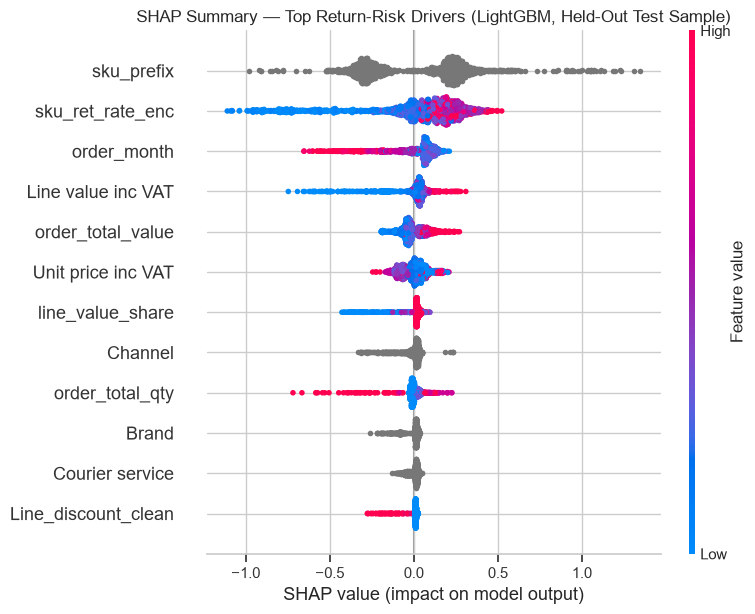

In [31]:
import shap

X_shap = X_test_cat.sample(n=min(1500, len(X_test_cat)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(lgb_model)
sv_raw = explainer.shap_values(X_shap)
shap_vals = sv_raw[1] if isinstance(sv_raw, list) else (sv_raw[:, :, 1] if sv_raw.ndim == 3 else sv_raw)

shap_imp = (
    pd.DataFrame({"Feature": FEATURE_COLS, "Mean_Abs_SHAP": np.abs(shap_vals).mean(axis=0)})
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .head(12)
)
display(shap_imp)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_shap, max_display=12, show=False)
plt.title("SHAP Summary — Top Return-Risk Drivers (LightGBM, Held-Out Test Sample)")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.4 Cost-Sensitive Threshold Optimization (£ Savings Curve)

Replaces generic F1 thresholding with a **business ROI objective** calibrated from `Returns.xlsx`:
- Effective avoided loss per prevented return = average direct return cost (£10.71) + `15%` handling/restocking friction on average refund (£52.14) ≈ **£18.53**
- Compares three pre-dispatch intervention cost tiers (**£0.25** automated sizing/fit-check email, **£0.50** SMS/guided check, and **£1.00** manual QA) assuming **25%** prevention on flagged true returns.
- Tunes each optimal cutoff strictly on **validation**, evaluates realized net £ savings on **test**, and exports `figures/08_cost_threshold_curve.png`.

,Intervention_Cost (£),BreakEven_Precision (%),Val_Optimal_Threshold,Test_Flagged,Test_True_Returns,Test_Net_Savings (£)
0,0.2500,5.4000,0.5000,1377,91,77.4100
1,0.5000,10.8000,0.6800,68,17,44.7700
2,1.0000,21.6000,0.6800,68,17,10.7700


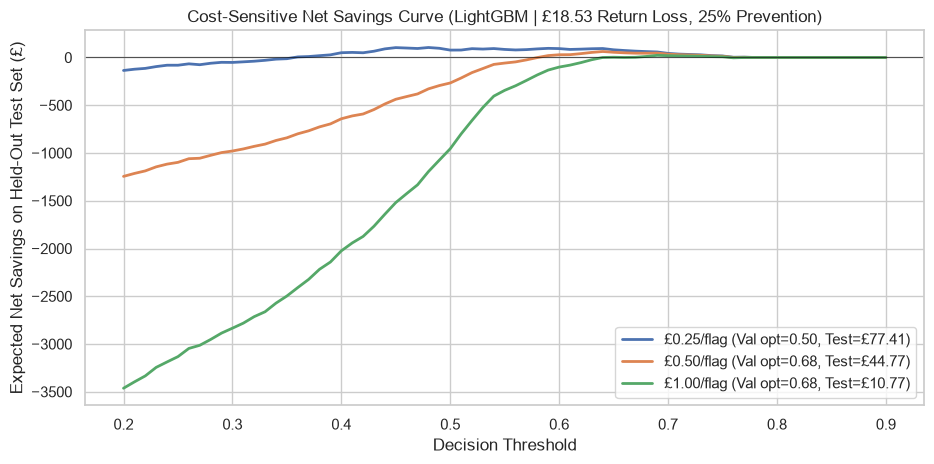

In [32]:
AVG_RETURN_LOSS = returns_df["Total return cost"].mean() + 0.15 * returns_df["Refund amount"].mean()
PREVENTION_RATE = 0.25

best_name_map = {
    "Logistic Regression (Balanced)": "Logistic Regression",
    "XGBoost (Native Cat + Tuned)": "XGBoost",
    "LightGBM (Native Cat + Balanced)": "LightGBM",
    "TabNet (Embeddings + Balanced)": "TabNet",
}
top_model_key = best_name_map[results_df.iloc[0]["Model"]]
val_p, test_p = val_prob_store[top_model_key], test_prob_store[top_model_key]

def calc_net_savings(y_true, probs, thresh, cost):
    flagged = (probs >= thresh).astype(int)
    tp = int(((flagged == 1) & (y_true == 1)).sum())
    n_flagged = int(flagged.sum())
    return tp * PREVENTION_RATE * AVG_RETURN_LOSS - n_flagged * cost, tp, n_flagged

grid = np.linspace(0.20, 0.90, 71)
cost_rows = []
fig, ax = plt.subplots(figsize=(9.5, 4.8))

for cost in [0.25, 0.50, 1.00]:
    val_s = [calc_net_savings(y_val, val_p, t, cost)[0] for t in grid]
    best_t = float(grid[int(np.argmax(val_s))])
    te_net, te_tp, te_flag = calc_net_savings(y_test, test_p, best_t, cost)
    breakeven_p = cost / (PREVENTION_RATE * AVG_RETURN_LOSS) * 100
    cost_rows.append({
        "Intervention_Cost (£)": cost,
        "BreakEven_Precision (%)": round(breakeven_p, 1),
        "Val_Optimal_Threshold": round(best_t, 2),
        "Test_Flagged": te_flag,
        "Test_True_Returns": te_tp,
        "Test_Net_Savings (£)": round(te_net, 2),
    })
    te_curve = [calc_net_savings(y_test, test_p, t, cost)[0] for t in grid]
    ax.plot(grid, te_curve, linewidth=2, label=f"£{cost:.2f}/flag (Val opt={best_t:.2f}, Test=£{te_net:,.2f})")

display(pd.DataFrame(cost_rows))
ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax.set_title(f"Cost-Sensitive Net Savings Curve ({top_model_key} | £{AVG_RETURN_LOSS:.2f} Return Loss, 25% Prevention)")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Expected Net Savings on Held-Out Test Set (£)")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "08_cost_threshold_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# Module 8: Forward-in-Time Chronological Validation (2025 → 2026)

Test true deployment realism by training on historical orders (`2025-01` to `2026-04`), tuning on `2026-05` to `2026-06`, and forecasting future orders (`2026-07` to `2026-09`).

### 8.1 Build Chronological Train / Val / Test Split

Splits `feat_df` strictly by `Order date` (`< 2026-05-01` train, `2026-05`–`2026-06` val, `>= 2026-07-01` test) and applies past-only OOF SKU target encoding.

In [33]:
t_train = feat_df[feat_df["Order date"] < "2026-05-01"].copy()
t_val = feat_df[(feat_df["Order date"] >= "2026-05-01") & (feat_df["Order date"] < "2026-07-01")].copy()
t_test = feat_df[feat_df["Order date"] >= "2026-07-01"].copy()

t_train, t_val, t_test = add_oof_sku_encoding(t_train, t_val, t_test)
Xt_tr_cat, Xt_va_cat, Xt_te_cat = build_native_cat_frames(t_train, t_val, t_test)
yt_tr, yt_va, yt_te = t_train["Returned"].astype(int).to_numpy(), t_val["Returned"].astype(int).to_numpy(), t_test["Returned"].astype(int).to_numpy()

for label, s_df in [("Temporal Train (<= Apr 2026)", t_train), ("Temporal Val (May-Jun 2026)", t_val), ("Temporal Test (Jul-Sep 2026)", t_test)]:
    print(f"{label:30s}: rows={len(s_df):5d} | return_rate={s_df['Returned'].mean()*100:.2f}%")

Temporal Train (<= Apr 2026)  : rows=23838 | return_rate=4.49%
Temporal Val (May-Jun 2026)   : rows= 5674 | return_rate=4.67%
Temporal Test (Jul-Sep 2026)  : rows= 4793 | return_rate=4.11%


### 8.2 Train & Evaluate Top Models on Future Orders (Jul–Sep 2026)

Evaluates Balanced Logistic Regression, Tuned XGBoost, and Balanced LightGBM under the strict forward-in-time split.

In [34]:
temporal_results = []

# 1) Logistic Regression
lr_t = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, C=1.0, random_state=RANDOM_STATE)),
])
lr_t.fit(t_train[FEATURE_COLS], yt_tr)
temporal_results.append(evaluate_model("Logistic Regression", yt_te, lr_t.predict_proba(t_test[FEATURE_COLS])[:, 1],
                                       tune_threshold(yt_va, lr_t.predict_proba(t_val[FEATURE_COLS])[:, 1]), verbose=False))

# 2) XGBoost
t_ratio = float((yt_tr == 0).sum() / max((yt_tr == 1).sum(), 1))
xgb_t = XGBClassifier(
    n_estimators=600, learning_rate=0.03, max_depth=4, min_child_weight=15,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=10.0,
    scale_pos_weight=t_ratio, tree_method="hist", enable_categorical=True,
    max_cat_to_onehot=4, eval_metric="aucpr", early_stopping_rounds=30,
    random_state=RANDOM_STATE, n_jobs=-1,
)
xgb_t.fit(Xt_tr_cat, yt_tr, eval_set=[(Xt_va_cat, yt_va)], verbose=False)
temporal_results.append(evaluate_model("XGBoost", yt_te, xgb_t.predict_proba(Xt_te_cat)[:, 1],
                                       tune_threshold(yt_va, xgb_t.predict_proba(Xt_va_cat)[:, 1]), verbose=False))

# 3) LightGBM
lgb_t = lgb.LGBMClassifier(
    objective="binary", metric="average_precision", is_unbalance=True, n_estimators=600, learning_rate=0.03,
    num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, random_state=RANDOM_STATE, verbose=-1,
)
lgb_t.fit(Xt_tr_cat, yt_tr, eval_set=[(Xt_va_cat, yt_va)],
          callbacks=[lgb.early_stopping(30, first_metric_only=True, verbose=False)])
temporal_results.append(evaluate_model("LightGBM", yt_te, lgb_t.predict_proba(Xt_te_cat)[:, 1],
                                       tune_threshold(yt_va, lgb_t.predict_proba(Xt_va_cat)[:, 1]), verbose=False))

temporal_df = pd.DataFrame(temporal_results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(temporal_df)

,Model,Threshold,ROC_AUC,PR_AUC,Precision_1,Recall_1,F1_1
0,Logistic Regression,0.6178,0.6612,0.0943,0.0929,0.1929,0.1254
1,LightGBM,0.6378,0.6212,0.0942,0.1522,0.1066,0.1254
2,XGBoost,0.5105,0.6425,0.0720,0.1056,0.1726,0.1310


### 8.3 Compare Customer-Grouped vs. Chronological Split Stability

Charts ROC-AUC and PR-AUC side by side across both split regimes to measure how robustly each model handles temporal drift. Exports `figures/09_temporal_comparison.png`.

,Model,ROC_AUC,PR_AUC,Split
0,LightGBM,0.6088,0.0938,Customer-Grouped
1,Logistic Regression,0.6208,0.0858,Customer-Grouped
2,XGBoost,0.6063,0.0724,Customer-Grouped
3,Logistic Regression,0.6612,0.0943,Chronological (Jul-Sep 2026)
4,LightGBM,0.6212,0.0942,Chronological (Jul-Sep 2026)
5,XGBoost,0.6425,0.0720,Chronological (Jul-Sep 2026)


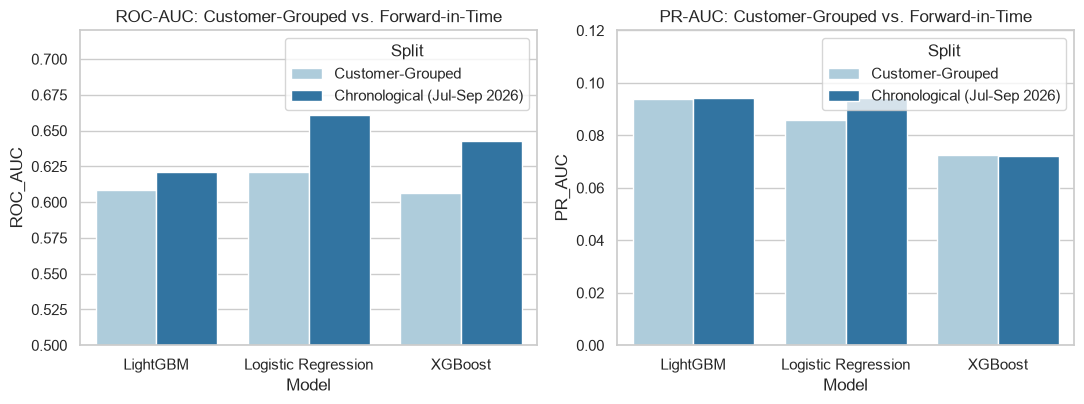

In [35]:
grp_sub = results_df.copy()
grp_sub["Model"] = grp_sub["Model"].map(best_name_map)
grp_sub = grp_sub[grp_sub["Model"].isin(["Logistic Regression", "XGBoost", "LightGBM"])][["Model", "ROC_AUC", "PR_AUC"]].assign(Split="Customer-Grouped")
tmp_sub = temporal_df[["Model", "ROC_AUC", "PR_AUC"]].assign(Split="Chronological (Jul-Sep 2026)")
comp_df = pd.concat([grp_sub, tmp_sub], ignore_index=True)
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.barplot(data=comp_df, x="Model", y="ROC_AUC", hue="Split", palette="Paired", ax=axes[0])
axes[0].set_title("ROC-AUC: Customer-Grouped vs. Forward-in-Time")
axes[0].set_ylim(0.50, 0.72)

sns.barplot(data=comp_df, x="Model", y="PR_AUC", hue="Split", palette="Paired", ax=axes[1])
axes[1].set_title("PR-AUC: Customer-Grouped vs. Forward-in-Time")
axes[1].set_ylim(0.0, 0.12)
plt.tight_layout()
fig.savefig(FIG_DIR / "09_temporal_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Module 9: Return Scrap-Risk Triage Model & Business Recommendations

Build a warehouse triage classifier on `Returns.xlsx` to predict whether an incoming return will be scrapped (`29.6%` scrap rate) vs. restocked, then synthesize all business findings.

### 9.1 Prepare Returns Dataset for Scrap Prediction (Customer-Grouped)

Constructs a customer-grouped 80/20 split of `returns_df` (1,523 records) using features available when a return request is logged (`Return reason`, `Brand`, `Channel`, `Courier service`, `Days to return`, `Units returned`, `Unit cost of goods`, `Refund amount`).

In [36]:
scrap_df = returns_df.copy()
scrap_df["is_scrapped"] = (scrap_df["Scrapped"] == "Yes").astype(int)

SCRAP_CATS = ["Return reason", "Brand", "Channel", "Courier service"]
SCRAP_NUMS = ["Days to return", "Units returned", "Unit cost of goods", "Refund amount"]
SCRAP_FEATS = SCRAP_CATS + SCRAP_NUMS

gss_scrap = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
s_tr_idx, s_te_idx = next(gss_scrap.split(scrap_df, scrap_df["is_scrapped"], groups=scrap_df["Customer ref"]))

X_s_tr, y_s_tr = scrap_df.iloc[s_tr_idx][SCRAP_FEATS], scrap_df.iloc[s_tr_idx]["is_scrapped"].to_numpy()
X_s_te, y_s_te = scrap_df.iloc[s_te_idx][SCRAP_FEATS], scrap_df.iloc[s_te_idx]["is_scrapped"].to_numpy()

print(f"Scrap Train: {len(X_s_tr)} (scrap={y_s_tr.mean()*100:.1f}%) | Scrap Test: {len(X_s_te)} (scrap={y_s_te.mean()*100:.1f}%)")

Scrap Train: 1229 (scrap=29.2%) | Scrap Test: 294 (scrap=31.3%)


### 9.2 Train Scrap-Risk Triage Classifier

Trains a balanced Logistic Regression pipeline to flag returns likely to be scrapped upon arrival (enabling fast-track refund-without-return or direct disposal triage when return shipping £5.22 exceeds salvage value).

In [37]:
scrap_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), SCRAP_CATS),
    ("num", StandardScaler(), SCRAP_NUMS),
])

scrap_pipe = Pipeline([
    ("prep", scrap_prep),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
scrap_pipe.fit(X_s_tr, y_s_tr)

scrap_probs = scrap_pipe.predict_proba(X_s_te)[:, 1]
scrap_preds = (scrap_probs >= 0.50).astype(int)
print(f"Scrap Model Test ROC-AUC: {roc_auc_score(y_s_te, scrap_probs):.4f} | PR-AUC: {average_precision_score(y_s_te, scrap_probs):.4f}")
print(classification_report(y_s_te, scrap_preds, target_names=["Restockable", "Scrapped"]))

Scrap Model Test ROC-AUC: 0.9281 | PR-AUC: 0.8882
              precision    recall  f1-score   support

 Restockable       0.94      0.93      0.94       202
    Scrapped       0.85      0.87      0.86        92

    accuracy                           0.91       294
   macro avg       0.90      0.90      0.90       294
weighted avg       0.91      0.91      0.91       294



### 9.3 Visualize Scrap Triage Confusion Matrix & Drivers

Plots the test confusion matrix alongside average predicted scrap probability by `Return reason`, highlighting clear operational separation. Exports `figures/10_scrap_model_cm.png`.

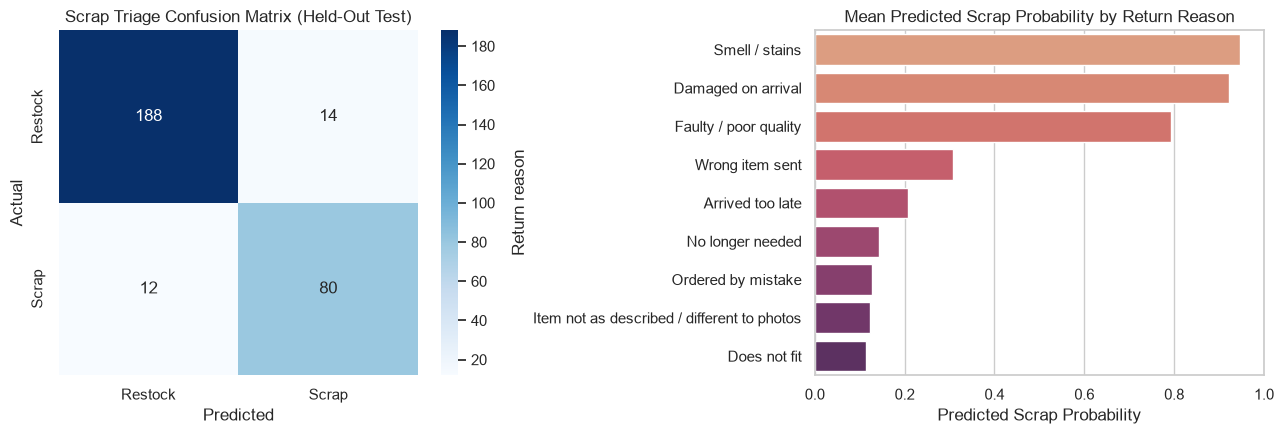

In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_s_te, scrap_preds)
reason_prob = (
    X_s_te.assign(Pred_Scrap_Prob=scrap_probs)
    .groupby("Return reason", as_index=False)["Pred_Scrap_Prob"]
    .mean()
    .sort_values("Pred_Scrap_Prob", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Restock", "Scrap"], yticklabels=["Restock", "Scrap"], ax=axes[0])
axes[0].set_title("Scrap Triage Confusion Matrix (Held-Out Test)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.barplot(data=reason_prob, y="Return reason", x="Pred_Scrap_Prob", hue="Return reason", palette="flare", legend=False, ax=axes[1])
axes[1].set_title("Mean Predicted Scrap Probability by Return Reason")
axes[1].set_xlabel("Predicted Scrap Probability")
axes[1].set_xlim(0, 1.0)
plt.tight_layout()
fig.savefig(FIG_DIR / "10_scrap_model_cm.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.4 Executive Summary & Actionable Business Recommendations

1. **Prioritize *Gardenista* Fit Guides & Photography:** *Gardenista* drives `4.89%` returns (vs. `2.03%` for *Game Over*), and `Does not fit` (`330`) + `Item not as described / different to photos` (`217`) account for over a third of all recorded returns.
2. **Eliminate Unnecessary Return Shipping on High-Scrap Reasons:** Our scrap triage model cleanly separates high-scrap reasons (`Smell / stains` `95.6%`, `Damaged on arrival` `87.9%`, `Faulty / poor quality` `65.9%`) from restockable reasons (`4%–8%`). For low-value high-scrap claims where shipping (£5.22) + handling exceeds salvage value, photo-verified keep-item refunds immediately cut reverse-logistics costs.
3. **Target High-Risk Products & Couriers:** SHAP and EDA highlight product family (`sku_prefix`), `Brand`, SKU return history (`sku_ret_rate_enc`), basket structure, and `Courier service` (`EVRI NEXT DAY` at `20.0%`, `BT Postcode - Do not Ship` at `66.7%`) as primary risk signals.
4. **Deploy Cost-Sensitive Intervention Rather Than Default 0.50 Cutoffs:** Under `4.5%` return prevalence, tuning thresholds to maximize expected £ savings (Module `7.4`) aligns model predictions directly with operational ROI.
5. **Fix Upstream Export Hygiene:** Reconcile the 10 £0-value returns missing from `Returns.xlsx`, cap `Line discount` at `100%` (currently `200` on 3 two-unit rows), and audit partial-unit return refund calculations.